# Weight Initialization Techniques

### All Weights initialized to zero:

Neurons in the same layer can identical features because of symmetry.

### All weights too large:

Activations and gradients may become excessively large, causing exploding gradients.

### All weights too small:

Signals and gradients can shrink thorugh layers, causing vanishing gradients.



## Weight initialization techniques

- Zero initialization
- Random initialization
- Xavier/Glorot
- He/Kaiming




## Xavier/Glorot


For uniform distribution.
It considers both the number of inputs and output. It is commonly used with tanh and sigmoid activations.


## He/Kaiming

For ReLu networks, It draws samples from a truncated normal distribution centered on 0 with stddev = sqrt(2 / fan_in) where fan_in is the number of input units in the weight tensor.

In [7]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras import layers,models


(X_train,y_train),(X_test,y_test)=(tf.keras.datasets.mnist.load_data())

print(X_train.shape)
print(X_test.shape)

(60000, 28, 28)
(10000, 28, 28)


In [8]:
X_train = X_train.astype("float32")/255.0
X_test = X_test.astype("float32")/255.0

print(X_train.shape)
print(X_test.shape)

(60000, 28, 28)
(10000, 28, 28)


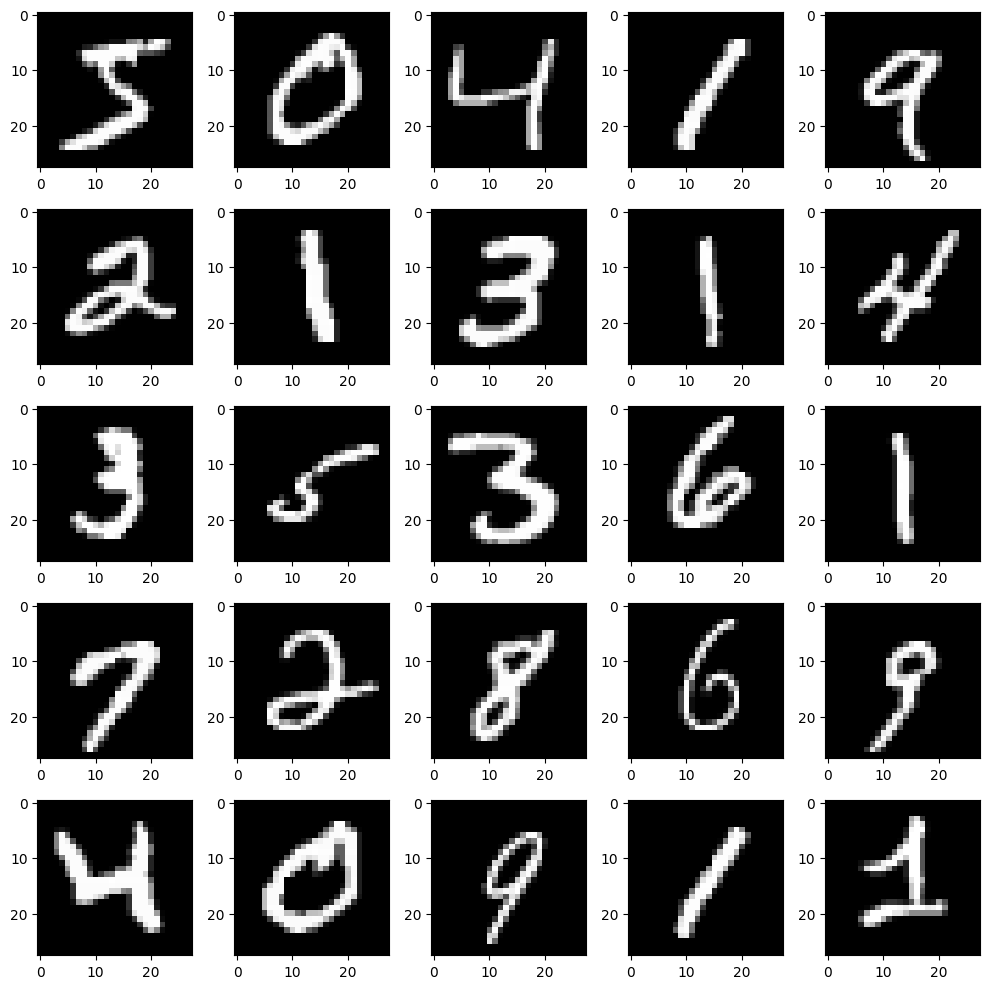

In [17]:
plt.figure(figsize=(10,10))
for i in range(25):
  plt.subplot(5,5,i+1)
  plt.imshow(X_train[i],cmap="gray")

plt.tight_layout()
plt.show()

In [18]:
from numpy._core.fromnumeric import shape
model = models.Sequential(
    [
        layers.Input(shape=(28,28)),
        layers.Flatten(),
        layers.Dense(128,activation="relu",kernel_initializer = tf.keras.initializers.RandomNormal(mean=0.0,stddev=0.05)),
        layers.Dense(64,activation="relu",kernel_initializer = tf.keras.initializers.RandomNormal(mean=0.0,stddev=0.05)),
        layers.Dense(10,activation="softmax",kernel_initializer = tf.keras.initializers.GlorotUniform())
    ]
)

model.compile(
    optimizer = "adam",
    loss = "sparse_categorical_crossentropy",
    metrics = ["accuracy"]
)

print(model.summary())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

None


In [19]:
model.fit(X_train,y_train,batch_size=128,epochs=10,verbose=2,validation_split=0.1)


Epoch 1/10
422/422 - 4s - 9ms/step - accuracy: 0.8907 - loss: 0.3929 - val_accuracy: 0.9533 - val_loss: 0.1639
Epoch 2/10
422/422 - 2s - 5ms/step - accuracy: 0.9550 - loss: 0.1560 - val_accuracy: 0.9643 - val_loss: 0.1223
Epoch 3/10
422/422 - 3s - 6ms/step - accuracy: 0.9675 - loss: 0.1097 - val_accuracy: 0.9697 - val_loss: 0.1018
Epoch 4/10
422/422 - 3s - 7ms/step - accuracy: 0.9748 - loss: 0.0833 - val_accuracy: 0.9745 - val_loss: 0.0884
Epoch 5/10
422/422 - 4s - 10ms/step - accuracy: 0.9799 - loss: 0.0660 - val_accuracy: 0.9757 - val_loss: 0.0840
Epoch 6/10
422/422 - 4s - 9ms/step - accuracy: 0.9831 - loss: 0.0543 - val_accuracy: 0.9773 - val_loss: 0.0812
Epoch 7/10
422/422 - 3s - 7ms/step - accuracy: 0.9870 - loss: 0.0430 - val_accuracy: 0.9760 - val_loss: 0.0849
Epoch 8/10
422/422 - 6s - 15ms/step - accuracy: 0.9888 - loss: 0.0362 - val_accuracy: 0.9760 - val_loss: 0.0882
Epoch 9/10
422/422 - 2s - 5ms/step - accuracy: 0.9904 - loss: 0.0303 - val_accuracy: 0.9773 - val_loss: 0.0889

In [20]:
model.evaluate(X_test,y_test,batch_size=32,verbose=2)

313/313 - 1s - 3ms/step - accuracy: 0.9752 - loss: 0.0840


[0.08397899568080902, 0.9751999974250793]

In [21]:
from numpy._core.fromnumeric import shape
model = models.Sequential(
    [
        layers.Input(shape=(28,28)),
        layers.Flatten(),
        layers.Dense(128,activation="relu",kernel_initializer = tf.keras.initializers.RandomUniform(minval=-0.05,maxval=0.05)),
        layers.Dense(64,activation="relu",kernel_initializer = tf.keras.initializers.RandomUniform(minval=-0.05,maxval=0.05)),
        layers.Dense(10,activation="softmax",kernel_initializer = tf.keras.initializers.GlorotUniform())
    ]
)

model.compile(
    optimizer = "adam",
    loss = "sparse_categorical_crossentropy",
    metrics = ["accuracy"]
)

print(model.summary())

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

None


In [22]:
model.fit(X_train,y_train,batch_size=128,epochs=10,verbose=2,validation_split=0.1)


Epoch 1/10
422/422 - 5s - 11ms/step - accuracy: 0.8843 - loss: 0.4142 - val_accuracy: 0.9523 - val_loss: 0.1811
Epoch 2/10
422/422 - 4s - 10ms/step - accuracy: 0.9469 - loss: 0.1813 - val_accuracy: 0.9633 - val_loss: 0.1303
Epoch 3/10
422/422 - 2s - 5ms/step - accuracy: 0.9630 - loss: 0.1258 - val_accuracy: 0.9687 - val_loss: 0.1028
Epoch 4/10
422/422 - 2s - 5ms/step - accuracy: 0.9717 - loss: 0.0957 - val_accuracy: 0.9728 - val_loss: 0.0936
Epoch 5/10
422/422 - 4s - 8ms/step - accuracy: 0.9777 - loss: 0.0758 - val_accuracy: 0.9733 - val_loss: 0.0877
Epoch 6/10
422/422 - 2s - 5ms/step - accuracy: 0.9818 - loss: 0.0602 - val_accuracy: 0.9753 - val_loss: 0.0878
Epoch 7/10
422/422 - 2s - 5ms/step - accuracy: 0.9839 - loss: 0.0525 - val_accuracy: 0.9753 - val_loss: 0.0867
Epoch 8/10
422/422 - 2s - 5ms/step - accuracy: 0.9870 - loss: 0.0424 - val_accuracy: 0.9793 - val_loss: 0.0780
Epoch 9/10
422/422 - 2s - 5ms/step - accuracy: 0.9897 - loss: 0.0340 - val_accuracy: 0.9767 - val_loss: 0.0849

In [23]:
model.evaluate(X_test,y_test,batch_size=32,verbose=2)


313/313 - 1s - 2ms/step - accuracy: 0.9753 - loss: 0.0891


[0.08912722766399384, 0.9753000140190125]

In [25]:
from numpy._core.fromnumeric import shape
model = models.Sequential(
    [
        layers.Input(shape=(28,28)),
        layers.Flatten(),
        layers.Dense(128,activation="relu",kernel_initializer = tf.keras.initializers.HeUniform()),
        layers.Dense(64,activation="relu",kernel_initializer = tf.keras.initializers.HeUniform()),
        layers.Dense(10,activation="softmax",kernel_initializer = tf.keras.initializers.GlorotUniform())
    ]
)

model.compile(
    optimizer = "adam",
    loss = "sparse_categorical_crossentropy",
    metrics = ["accuracy"]
)

print(model.summary())

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_3 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

None


In [26]:
model.fit(X_train,y_train,batch_size=128,epochs=10,verbose=2,validation_split=0.1)


Epoch 1/10
422/422 - 3s - 8ms/step - accuracy: 0.9010 - loss: 0.3452 - val_accuracy: 0.9572 - val_loss: 0.1488
Epoch 2/10
422/422 - 2s - 5ms/step - accuracy: 0.9592 - loss: 0.1382 - val_accuracy: 0.9693 - val_loss: 0.1069
Epoch 3/10
422/422 - 3s - 7ms/step - accuracy: 0.9706 - loss: 0.0979 - val_accuracy: 0.9737 - val_loss: 0.0873
Epoch 4/10
422/422 - 3s - 7ms/step - accuracy: 0.9769 - loss: 0.0755 - val_accuracy: 0.9722 - val_loss: 0.0841
Epoch 5/10
422/422 - 5s - 11ms/step - accuracy: 0.9824 - loss: 0.0581 - val_accuracy: 0.9735 - val_loss: 0.0808
Epoch 6/10
422/422 - 2s - 5ms/step - accuracy: 0.9859 - loss: 0.0472 - val_accuracy: 0.9772 - val_loss: 0.0772
Epoch 7/10
422/422 - 3s - 7ms/step - accuracy: 0.9882 - loss: 0.0376 - val_accuracy: 0.9790 - val_loss: 0.0722
Epoch 8/10
422/422 - 3s - 7ms/step - accuracy: 0.9917 - loss: 0.0299 - val_accuracy: 0.9768 - val_loss: 0.0884
Epoch 9/10
422/422 - 2s - 5ms/step - accuracy: 0.9924 - loss: 0.0254 - val_accuracy: 0.9770 - val_loss: 0.0795


In [27]:
model.evaluate(X_test,y_test,batch_size=32,verbose=2)


313/313 - 1s - 2ms/step - accuracy: 0.9751 - loss: 0.0840


[0.08403429388999939, 0.9750999808311462]